In [55]:
import pandas as pd

data = {
    "Product": [
        " Laptop ", "Mouse", "keyboard ", "Laptop",
        " Mouse ", "Monitor", "Keyboard", "Monitor"
    ],
    "Quantity": [
        "2", "5", "three", "1", "4", None, "6", "2"
    ],
    "Unit_Price": [
        "50000", "700", "1,200", "50000",
        "700", "12000", "1,200", "12,000"
    ],
    "City": [
        "Ahmedabad", "Surat", "Vadodara", "Surat",
        "Ahmedabad", "Ahmedabad", "surat ", "Vadodara"
    ],
    "Rating": [
        5, 4, 4, 5, None, 3, 4, 3
    ]
}
df = pd.DataFrame(data)
df

,Product,Quantity,Unit_Price,City,Rating
0,Laptop,2,50000,Ahmedabad,5.0
1,Mouse,5,700,Surat,4.0
2,keyboard,three,"1,200",Vadodara,4.0
3,Laptop,1,50000,Surat,5.0
4,Mouse,4,700,Ahmedabad,NaN
5,Monitor,None,12000,Ahmedabad,3.0
6,Keyboard,6,"1,200",surat,4.0
7,Monitor,2,"12,000",Vadodara,3.0


In [56]:
#2 Inspect the data

# head() shows the first five rows.
print(df.head())

# shape shows the number of rows and columns.
print(df.shape)

# dtypes shows the data types.
print(df.dtypes)

# isnull().sum() counts missing values in each column.
print(df.isnull().sum())

     Product Quantity Unit_Price       City  Rating
0    Laptop         2      50000  Ahmedabad     5.0
1      Mouse        5        700      Surat     4.0
2  keyboard     three      1,200   Vadodara     4.0
3     Laptop        1      50000      Surat     5.0
4     Mouse         4        700  Ahmedabad     NaN
(8, 5)
Product        object
Quantity       object
Unit_Price     object
City           object
Rating        float64
dtype: object
Product       0
Quantity      1
Unit_Price    0
City          0
Rating        1
dtype: int64


In [57]:
# Clean the Product and City columns.
df["Product"] = df["Product"].str.strip()
df["City"] = df["City"].str.strip()
df[["Product","City"]]

,Product,City
0,Laptop,Ahmedabad
1,Mouse,Surat
2,keyboard,Vadodara
3,Laptop,Surat
4,Mouse,Ahmedabad
5,Monitor,Ahmedabad
6,Keyboard,surat
7,Monitor,Vadodara


In [58]:
# Standardize City column
df["City"] = df["City"].str.title()
df["City"]


0    Ahmedabad
1        Surat
2     Vadodara
3        Surat
4    Ahmedabad
5    Ahmedabad
6        Surat
7     Vadodara
Name: City, dtype: object

In [59]:
# Convert Quantity into numbers
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Quantity"]

0    2.0
1    5.0
2    NaN
3    1.0
4    4.0
5    NaN
6    6.0
7    2.0
Name: Quantity, dtype: float64

In [60]:
# Unit_Price conversion
df["Unit_Price"] = df["Unit_Price"].str.replace(",","")
df["Unit_Price"]  = pd.to_numeric(df["Unit_Price"], errors="coerce")

print(df["Unit_Price"])
print(df.dtypes)

0    50000
1      700
2     1200
3    50000
4      700
5    12000
6     1200
7    12000
Name: Unit_Price, dtype: int64
Product        object
Quantity      float64
Unit_Price      int64
City           object
Rating        float64
dtype: object


In [61]:
# Handle missing values
df.isnull().sum()
print(df["Quantity"])
# Handle missing Quantity
median_quantity = df["Quantity"].median()
df["Quantity"] = df["Quantity"].fillna(median_quantity)
df["Quantity"]


0    2.0
1    5.0
2    NaN
3    1.0
4    4.0
5    NaN
6    6.0
7    2.0
Name: Quantity, dtype: float64


0    2.0
1    5.0
2    3.0
3    1.0
4    4.0
5    3.0
6    6.0
7    2.0
Name: Quantity, dtype: float64

In [62]:
# Handle missing Rating
print(df["Rating"])
median_rating = df["Rating"].median()
median_rating
df["Rating"] = df["Rating"].fillna(median_rating)
df["Rating"]
df.isnull().sum()

0    5.0
1    4.0
2    4.0
3    5.0
4    NaN
5    3.0
6    4.0
7    3.0
Name: Rating, dtype: float64


Product       0
Quantity      0
Unit_Price    0
City          0
Rating        0
dtype: int64

In [63]:
# Check for duplicate rows
df.duplicated().sum()
# To remove duplicates if they exist, we can use:
df = df.drop_duplicates()
df

,Product,Quantity,Unit_Price,City,Rating
0,Laptop,2.0,50000,Ahmedabad,5.0
1,Mouse,5.0,700,Surat,4.0
2,keyboard,3.0,1200,Vadodara,4.0
3,Laptop,1.0,50000,Surat,5.0
4,Mouse,4.0,700,Ahmedabad,4.0
5,Monitor,3.0,12000,Ahmedabad,3.0
6,Keyboard,6.0,1200,Surat,4.0
7,Monitor,2.0,12000,Vadodara,3.0


In [64]:
# Calculate revenue using Pandas
df["Revenue"] = df["Quantity"] * df["Unit_Price"]
df

,Product,Quantity,Unit_Price,City,Rating,Revenue
0,Laptop,2.0,50000,Ahmedabad,5.0,100000.0
1,Mouse,5.0,700,Surat,4.0,3500.0
2,keyboard,3.0,1200,Vadodara,4.0,3600.0
3,Laptop,1.0,50000,Surat,5.0,50000.0
4,Mouse,4.0,700,Ahmedabad,4.0,2800.0
5,Monitor,3.0,12000,Ahmedabad,3.0,36000.0
6,Keyboard,6.0,1200,Surat,4.0,7200.0
7,Monitor,2.0,12000,Vadodara,3.0,24000.0


In [68]:
# Group sales by product
product_sales = df.groupby("Product")["Revenue"].sum()
product_sales

Product
Keyboard      7200.0
Laptop      150000.0
Monitor      60000.0
Mouse         6300.0
keyboard      3600.0
Name: Revenue, dtype: float64

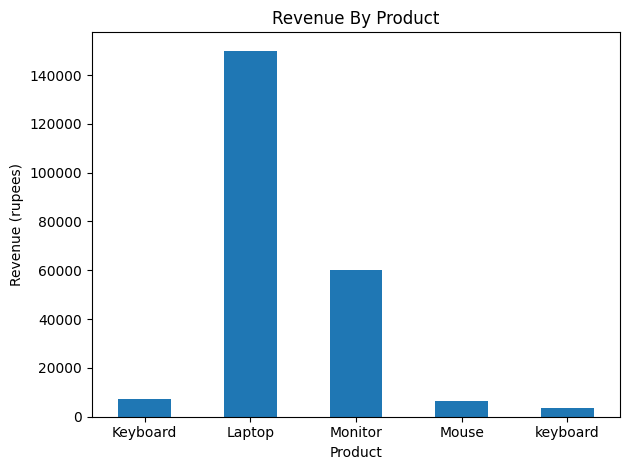

In [74]:
import matplotlib.pyplot as plt

product_sales.plot(kind="bar")
plt.title("Revenue By Product")
plt.xlabel("Product")
plt.ylabel("Revenue (rupees)")
plt.xticks(rotation=0) #keeps product labels horizontal.
plt.tight_layout() #helps prevent labels from being cut off.
plt.show()
